## Port accessibility - real-world example

In this notebook, we set up a model for a real-world example in the Port of Rotterdam using real-world data sources. We simulate Panamax vessels with a length of 200 m and a draught of 14.65, calling at a terminal of the 3e Petroleumhaven. This terminal is a liquid bulk terminal and has two suitable jetties for this vessel type. To reach the terminal, the vessels have to navigate the Nieuwe Waterweg. Here, the vessels experience tidal windows. There assume no one-way traffic restrictions.

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from pyproj import Geod
from shapely.geometry import Point, LineString

# package(s) related to the hydrodynamics and tidal windows
import xarray as xr

# load OpenTNSim core mixins
from opentnsim.core import Identifiable, Movable, VesselProperties, ExtraMetadata
from opentnsim.core.logutils import logbook2eventtable
from opentnsim.core.utils import create_object, inspect_object
from opentnsim.core.visualizations import generate_vessel_gantt_chart

# load OpenTNSim environment mixin to add hydrodynamic data to the environment
from opentnsim.environment.mixins.hydrodynamics import HydrodynamicData
from opentnsim.environment.utils import (
    create_default_hydrodynamic_dataset,
    add_lonlat_to_xr_dataset, 
    add_closest_node_to_xr_dataset, 
    add_specific_environmental_data,
    overwrite_data_on_node_with_data_from_another_node,
    interpolate_data_on_route,
    set_station_value,
)

# load OpenTNSim graph utils
from opentnsim.graph.mixins import FIS
from opentnsim.graph.calculations import calculate_distance_along_path
from opentnsim.graph.utils import get_closest_node_to_geometry
from opentnsim.graph.visualizations import plot_graph

from opentnsim.model import Simulation

# load OpenTNSim port module mixins and utils
from opentnsim.port.mixins.rules import Rule, TrafficRules
from opentnsim.port.mixins.tidal_accessibility import HasDraughtRestrictions
from opentnsim.port.mixins.anchorage_area import IsAnchorage, CanWaitAtAnchorage
from opentnsim.port.mixins.port import IsPort, HasPortAccess
from opentnsim.port.mixins.berth import IsJetty, IsQuay
from opentnsim.port.mixins.terminal import IsTerminal, TerminalHandable
from opentnsim.port.mixins.waterway import IsWaterway, WaterwayTraversable
from opentnsim.port.visualizations import plot_vessels_over_route
from opentnsim.port.utils import (
    add_ukc_policy_to_node, 
    add_traffic_encountering_restriction_to_edge, 
    add_traffic_encountering_exception_to_edge,
    add_traffic_overtaking_restriction_to_edge, 
    add_traffic_reservation_to_edge,
)

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim
import geopandas as gpd
from itertools import combinations

# package(s) needed for inspecting the output
import pandas as pd
import numpy as np
from IPython.display import HTML, display

# package(s) for plotting
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# package(s) for setting paths
from pathlib import Path

print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


In [2]:
data_path = Path.cwd() / 'data' / 'Port_accessibility'

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import numpy as np
import pandas as pd
import datetime
from scipy.stats import truncnorm

def generate_vessels_from_distributions(
    vessel_class_specs,
    vessel_class_probabilities,
    number_of_vessels,
    mean_interarrival_time,
    simulation_start,
    maximum_draught=None,
    correlation_beam_draught=0.4,
    seed=None,
):

    # 1. Initialize random generators
    rng_class = np.random.default_rng(seed)
    rng_length = np.random.default_rng(seed + 1)
    rng_beam_draught = np.random.default_rng(seed + 2)
    rng_mooring = np.random.default_rng(seed + 3)
    rng_cargo = np.random.default_rng(seed + 4)
    rng_block = np.random.default_rng(seed + 5)
    rng_transfer_rate = np.random.default_rng(seed + 6)
    rng_demooring = np.random.default_rng(seed + 7)
    rng_interarrival = np.random.default_rng(seed + 8)

    # 2. Sample vessel classes
    vessel_classes = list(vessel_class_probabilities.keys())
    vessel_class_p = list(vessel_class_probabilities.values())

    if not np.isclose(sum(vessel_class_p), 1.0):
        raise ValueError("Vessel class probabilities must sum to 1.")

    vessel_class_sample = rng_class.choice(
        vessel_classes,
        size=number_of_vessels,
        p=vessel_class_p
    )

    vessels = []

    # 3. Generate individual vessels
    for vessel_class in vessel_class_sample:

        p = vessel_class_specs.loc[
            vessel_class_specs["class"] == vessel_class
        ].iloc[0]

        # Length: truncated normal distribution
        mu_L = p["length_mean"]
        sigma_L = p["length_std"]

        lower = mu_L - 2 * sigma_L
        upper = mu_L + 2 * sigma_L

        length = truncnorm.rvs(
            (lower - mu_L) / sigma_L,
            (upper - mu_L) / sigma_L,
            loc=mu_L,
            scale=sigma_L,
            random_state=rng_length
        )

        # Beam and draught ratios: correlated normal distributions
        mu_B = p["beam_ratio_mean"]
        sigma_B = p["beam_ratio_std"]

        mu_T = p["draught_ratio_mean"]
        sigma_T = p["draught_ratio_std"]

        covariance = [
            [
                sigma_B**2,
                correlation_beam_draught * sigma_B * sigma_T
            ],
            [
                correlation_beam_draught * sigma_B * sigma_T,
                sigma_T**2
            ]
        ]

        beam_ratio, draught_ratio = rng_beam_draught.multivariate_normal(
            [mu_B, mu_T],
            covariance
        )

        beam = length * beam_ratio
        draught = length * draught_ratio

        # Optional maximum draught
        if maximum_draught is not None:
            draught = min(draught, maximum_draught)

        if beam <= 0 or draught <= 0:
            raise ValueError("Generated non-positive vessel dimension.")

        # Block coefficient
        block_coefficient = rng_block.triangular(
            p["block_coefficient_min"],
            p["block_coefficient_mean"],
            p["block_coefficient_max"]
        )

        # Cargo fraction
        cargo_fraction = rng_cargo.triangular(
            p["cargo_fraction_min"],
            p["cargo_fraction_mean"],
            p["cargo_fraction_max"]
        )

        # Approximate displacement and cargo quantity
        seawater_density = 1.025

        displacement = (
            length * beam * draught
            * block_coefficient
            * seawater_density
        )

        cargo_tonnes = displacement * cargo_fraction

        # Transfer rate
        transfer_rate = rng_transfer_rate.triangular(
            p["transfer_rate_min"],
            p["transfer_rate_mean"],
            p["transfer_rate_max"]
        )

        # Cargo operation time
        operation_time = cargo_tonnes / transfer_rate

        # Mooring time
        mooring_time = rng_mooring.triangular(
            p["mooring_time_min"],
            p["mooring_time_mode"],
            p["mooring_time_max"]
        )

        # Demooring time
        demooring_time = rng_demooring.triangular(
            p["demooring_time_min"],
            p["demooring_time_mode"],
            p["demooring_time_max"]
        )

        vessels.append({
            "class": vessel_class,
            "length": length,
            "beam": beam,
            "draught": draught,
            "cargo_tonnes": cargo_tonnes,
            "transfer_rate_tph": transfer_rate,
            "operation_time_hours": operation_time,
            "mooring_time_hours": mooring_time,
            "demooring_time_hours": demooring_time
        })

    # 4. Create DataFrame
    vessels_df = pd.DataFrame(vessels)

    # 5. Generate interarrival times
    interarrival_times = rng_interarrival.exponential(
        scale=mean_interarrival_time,
        size=number_of_vessels
    )

    arrival_hours = np.cumsum(interarrival_times)

    # 6. Add arrival information
    vessels_df["interarrival_time_hours"] = interarrival_times

    vessels_df["arrival_time_hours"] = arrival_hours

    vessels_df["arrival_time"] = [
        simulation_start + datetime.timedelta(hours=float(t))
        for t in arrival_hours
    ]

    # 7. Round numerical values
    vessels_df = vessels_df.round({
        "length": 2,
        "beam": 2,
        "draught": 2,
        "cargo_tonnes": 0,
        "transfer_rate_tph": 2,
        "operation_time_hours": 2,
        "mooring_time_hours": 2,
        "demooring_time_hours": 2,
        "interarrival_time_hours": 2,
        "arrival_time_hours": 2
    })

    return vessels_df

#### 0. Create environment

In [5]:
# set simulation time
simulation = Simulation(
    simulation_start = datetime.datetime(2026, 1, 1, 0, 0, 0),
    simulation_stop = datetime.datetime(2026, 2, 1, 0, 0, 0),
)
env = simulation.env

In [6]:
deepening = 2 #m

#### 1. Create graph
Next we create a network (a graph) along which the vessels can navigate. For this case we use the Fairway Information System graph, and consider the Port of Rotterdam.

In [7]:
# load the processed version from the Fairway Information System graph provided by Rijkswaterstaat
FG = FIS.load_network(version="0.3")

In the North Sea, there is a Traffic Separation Scheme (TSS) that separates traffic flows. There are one-way traffic waterways and there is a two-way deepwater route. To implement this, we convert the nx.Graph to a directed nx.DiGraph.

In [8]:
FG = nx.DiGraph(FG)

And we add the specific restrictions:

In [9]:
# adding one-way traffic West - East corridor
routeWE1a = nx.dijkstra_path(FG, '8863654', '8863061', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeWE1a)
for edge in edges:
    FG.edges[edge]['length_m'] = float('inf')

routeWE2a = nx.dijkstra_path(FG, '8862396', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeWE2a)
for edge in edges:
    FG.edges[edge]['length_m'] = float('inf')

# adding one-way traffic North West - South East corridor
routeNWSE1a = nx.dijkstra_path(FG, '8863654', '8863672', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNWSE1a)
for edge in edges:
    FG.edges[edge]['length_m'] = float('inf')

routeNWSE2a = nx.dijkstra_path(FG, '8864322', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNWSE2a)
for edge in edges:
    FG.edges[edge]['length_m'] = float('inf')

# adding one-way traffic North - South corridor
routeNS1a = nx.dijkstra_path(FG, '9928450', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNS1a)
for edge in edges:
    FG.edges[edge]['length_m'] = float('inf')

routeNS2a = nx.dijkstra_path(FG, '8863654', '8863704', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNS2a)
for edge in edges:
    FG.edges[edge]['length_m'] = float('inf')

routeWE1b = nx.dijkstra_path(FG, '8863061', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeWE1b)
for edge in edges:
    FG.edges[edge]['max_draught'] = 17.4

routeWE2b = nx.dijkstra_path(FG, '8863654', '8862396', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeWE2b)
for edge in edges:
    FG.edges[edge]['max_draught'] = 17.4

routeNWSE1b = nx.dijkstra_path(FG, '8863672', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNWSE1b)
for edge in edges:
    FG.edges[edge]['max_draught'] = 17.4

routeNWSE2b = nx.dijkstra_path(FG, '8863654', '8864322', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNWSE2b)
for edge in edges:
    FG.edges[edge]['max_draught'] = 17.4

routeNS1b = nx.dijkstra_path(FG, '8863654', '9928450', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNS1b)
for edge in edges:
    FG.edges[edge]['max_draught'] = 17.4

routeNS2b = nx.dijkstra_path(FG, '8862413', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeNS2b)
for edge in edges:
    FG.edges[edge]['max_draught'] = 17.4

routeEMGa = nx.dijkstra_path(FG, '8863777', '8863654', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeEMGa)
for edge in edges:
    FG.edges[edge]['min_draught'] = 17.4
    edge_rev = edge[::-1]
    FG.edges[edge_rev]['min_draught'] = 17.4

routeEMGb = nx.dijkstra_path(FG, '8863654', '8863777', weight='length_m')
edges = opentnsim.graph.utils.node_path_to_edge_path(FG, routeEMGb)
for edge in edges:
    FG.edges[edge]['min_draught'] = 17.4
    edge_rev = edge[::-1]
    FG.edges[edge_rev]['min_draught'] = 17.4

routeEMG_tot = nx.dijkstra_path(FG, '8863777', '8866969', weight='length_m')
routeNorthSeaTSS = nx.shortest_path(FG, '8866318', '8864535') #weight='length_m' gives wrong route

We add the graph to the environment

In [10]:
simulation.add_graph(FG)

And we plot the graph (warning: the plot can be demanding for your PC)

In [11]:
#opentnsim.graph.visualizations.plot_graph_folium(env.graph, longitude=4.25, latitude=51.95, zoom_start=11)

#### 1+ Environmental data
We add tidal water levels and nautical depths to the simulation

In [12]:
hydrodynamic_data = xr.open_dataset(data_path / 'hydrodynamic_data_PoR.nc')
nodes_shallow_waterway = nx.shortest_path(FG, '8866969', '8866999')
hydrodynamic_data['Nautical depth'].loc[dict(STATION=nodes_shallow_waterway)] -= deepening
data = HydrodynamicData(env=env, hydrodynamic_data = hydrodynamic_data)

##### Tidal window restrictions
We need to specify the tidal window restrictions for each node. Also for this, we gather information from the Port of Rotterdam, and prepared a dataframe with data on UKC (under-keel clearance) and FWA (freshwater allowance).

In [13]:
def ukc_policy(vessel, ukc_p, ukc_s, fwa):
    draught = vessel.T
    ukc = draught*(ukc_p + fwa) + ukc_s
    return ukc

In [14]:
ukc_policy_df = pd.read_pickle(data_path / 'ukc_policy_PoR.pickle')
ukc_policy_df

,ukc_p,ukc_s,fwa
8866969,0.1,0.0,0.0125
8866305,0.1,0.0,0.0125
8864266,0.1,0.0,0.0125
8862925,0.1,0.0,0.0125
8864465,0.1,0.0,0.0125
S14716_B,0.1,0.0,0.0125
S14716_A,0.1,0.0,0.0125
8860845,0.1,0.0,0.0125
8861674,0.1,0.0,0.0250
8861158,0.1,0.0,0.0250


In [15]:
for node in env.graph.nodes:
    if node not in ukc_policy_df.index:
        continue

    ukc_p = ukc_policy_df.loc[node].ukc_p
    ukc_s = ukc_policy_df.loc[node].ukc_s
    fwa = ukc_policy_df.loc[node].fwa
    
    # we create a list of Rule-objects that have a condition, policy, and name
    rules = [
        Rule(
            condition=lambda vessel: vessel.T >= 0.,
            policy=lambda vessel, ukc_p=ukc_p, ukc_s=ukc_s, fwa=fwa: ukc_policy(
                vessel,
                ukc_p=ukc_p,
                ukc_s=ukc_s,
                fwa=fwa
            ),
            name='ukc',
        ),
    ]

    # a built-in function that adds the rule(s) to the defined edge of the environment's graph
    add_ukc_policy_to_node(
        env=env,
        node=node,
        rules=rules,
    )

#### 1+ Infrastructure
We have to schematize a terminal. For this, we can download geometries of berths. For this, we use the [Havenkaart (Port Map) of the Port of Rotterdam](https://experience.arcgis.com/experience/aef5cad4ef6a437499c2ba6a7606c07b/page/Harbour-Master-Port-Map). 

##### Port
We start by creating the port itself. For simplicity, given the plot of the graph above, we take node "8866969" as our port entry.

In [16]:
port = IsPort(env=env, name = "Port of Rotterdam", port_entry_nodes=['8866318'])

##### Anchorage area
There are multiple anchorage areas in the Port of Rotterdam. They are located at sea (see [Havenkaart](https://experience.arcgis.com/experience/aef5cad4ef6a437499c2ba6a7606c07b/page/Harbour-Master-Port-Map)). For simplicity, we create a single imaginary anchorage area at the port entry with a depth of 25.0 m, which will be more than sufficient for our vessels. This will have no effect on the results.

In [17]:
anchorage_area_depth = 20.
anchorage_capacity = 20.
anchorage = IsAnchorage(
    env=env, 
    capacity=anchorage_capacity, 
    name = 'Anchorage', 
    node = '30986312', 
    depth = anchorage_area_depth, 
    geometry=env.graph.nodes['8866969']['geometry'], 
    port = port,
)

##### Terminal and berths
For one of the terminals of the 3e Petroleumhaven, we prepared a geodataframe with berths that are suitable for our vessels.

In [18]:
berth_df = pd.read_pickle(data_path / "berth_df_PoR.pickle")
berth_df

,terminal_name,berth_name,berth_type,length,depth,node
0,Chane,Steiger 6 buiten,Jetty,253,15.9,8866999
1,Chane,Steiger 7 buiten,Jetty,190,15.9,8866999
2,Chane,Steiger 9 buiten,Jetty,208,12.65,8866999
3,Chane,Steiger 10 buiten,Jetty,275,17.0,8866999
4,Chane,Kade 11,Jetty,190,12.65,8866999


We use the dataframe to create jetties that serve as berths for our terminal

In [19]:
berths = []
for _, berth in berth_df.iterrows():
    if berth.berth_type == 'Jetty':
        berth = IsJetty(
            env=env, 
            length=berth.length, 
            depth=berth.depth, 
            name=berth.berth_name,
            node=berth.node,
        )
    elif berth.berth_type == 'Quay':
        berth = IsQuay(
            env=env, 
            length=berth.length, 
            depth=berth.depth, 
            name=berth.berth_name,
            node=berth.node,
        )
    
    berths.append(berth)

We can now create the terminal

In [20]:
terminal = IsTerminal(
    env=env, 
    name = 'Chane', 
    berths = berths, 
    port = port,
)

#### 2. Create agents

In [21]:
# make your preferred Vessel class out of available mix-ins.
Vessel = create_object(
    "Vessel", 
    (HasPortAccess,
     TerminalHandable,
     CanWaitAtAnchorage,
     WaterwayTraversable,
     HasDraughtRestrictions,
     Movable,      # allows the object to move, with a fixed speed, while logging this activity
     VesselProperties,
    ), 
)

In [22]:
def mission(env, vessel):
    """
    Method that defines the mission of the vessel. 
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    yield from vessel.move()

In [23]:
tanker_classes_df = pd.read_pickle(data_path / 'tanker_classes_df.pkl')

tanker_class_probabilities = {
    "Coaster": 0.528,
    "Handysize": 0.322,
    "Panamax": 0.125,
    "Aframax": 0.023,
    "Suezmax": 0.002,
    "VLCC": 0.00,
}

number_of_vessels = 80
mean_interarrival_time = (env.simulation_stop - env.simulation_start).total_seconds() / 3600 / number_of_vessels
maximum_length = 275
maximum_draught = 15.0

vessels_df = generate_vessels_from_distributions(
    vessel_class_specs = tanker_classes_df,
    vessel_class_probabilities = tanker_class_probabilities,
    number_of_vessels = number_of_vessels,
    mean_interarrival_time = mean_interarrival_time,
    simulation_start = env.simulation_start,
    maximum_draught = maximum_draught,
    seed = 456,
)

for index, vessel_info in vessels_df.iterrows():
    data_vessel = {
        "env": env,                                      
        "name": f"Vessel {index}",                               
        "origin":'8866318',
        "destination":'8866999',
        "v": 4.5,                                
        "bound": 'inbound',
        "terminal": terminal,
        "berthing_time": vessel_info['mooring_time_hours']*60,
        "loading_time": vessel_info['operation_time_hours'],
        "deberthing_time": vessel_info['demooring_time_hours']*60,
        "next_destination":'8866318',
        "type":f"Tanker ({vessel_info['class']})",
        "L":vessel_info['length'],
        "B":vessel_info['beam'],
        "T":vessel_info['draught'],
        "arrival_time":vessel_info['arrival_time'],
    } 

    vessel = Vessel(**data_vessel)
    simulation.add_vessel(vessel, mission)

#### 3. Run simulation

In [24]:
simulation.run()

0 days 09:05:23.999999999 2026-01-01 13:26:24.910041 0 days 08:43:48
1 days 04:18:00 2026-01-01 22:32:06.425662 1 days 04:01:12
0 days 09:04:12 2026-01-03 00:54:25.804432 0 days 08:48:00
1 days 14:52:12 2026-01-03 01:47:42.381077 1 days 14:30:00
2 days 20:48:36 2026-01-03 03:19:18.218423 2 days 20:28:12
1 days 07:27:36 2026-01-03 10:14:20.648313 1 days 07:11:24
1 days 02:42:35.999999999 2026-01-03 13:21:41.115606 1 days 02:28:12
1 days 08:49:47.999999999 2026-01-03 19:27:56.084040 1 days 08:28:47.999999999
1 days 06:35:24 2026-01-04 16:23:29.115606 1 days 06:17:24
0 days 17:24:00 2026-01-04 23:16:10.975696 0 days 17:05:24
1 days 09:18:00 2026-01-05 02:57:00.760422 1 days 08:57:00
2 days 15:10:48 2026-01-05 04:45:56.084039 2 days 14:49:48
0 days 14:50:24 2026-01-05 17:05:23 0 days 14:34:12
0 days 12:04:48 2026-01-05 23:16:53.115606 0 days 11:45:00
0 days 23:30:00 2026-01-06 22:36:25.870071 0 days 23:12:36
1 days 03:55:12 2026-01-07 13:22:41.004748 1 days 03:34:48
0 days 11:31:11.9999999

#### 4. Inspect output

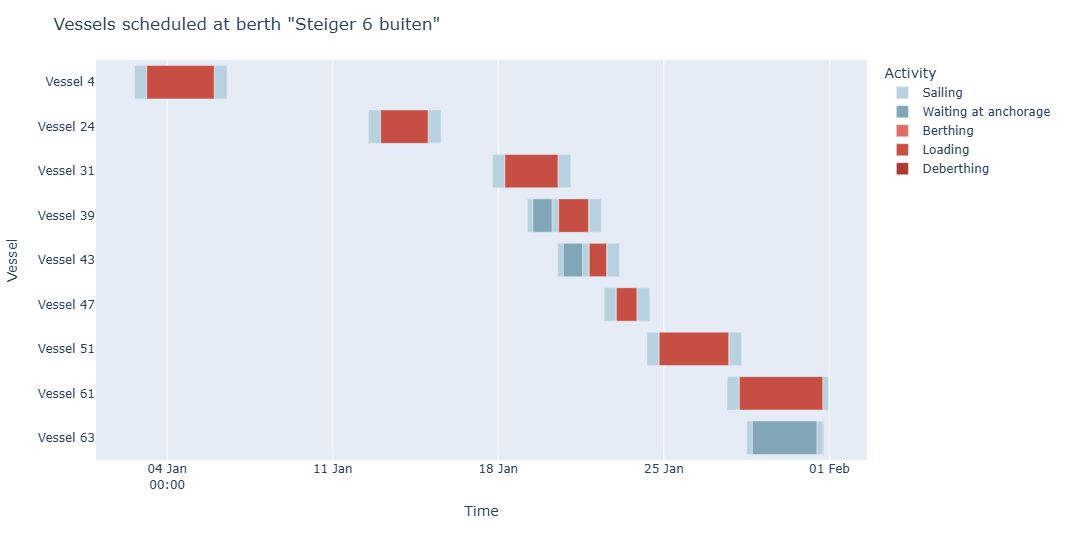

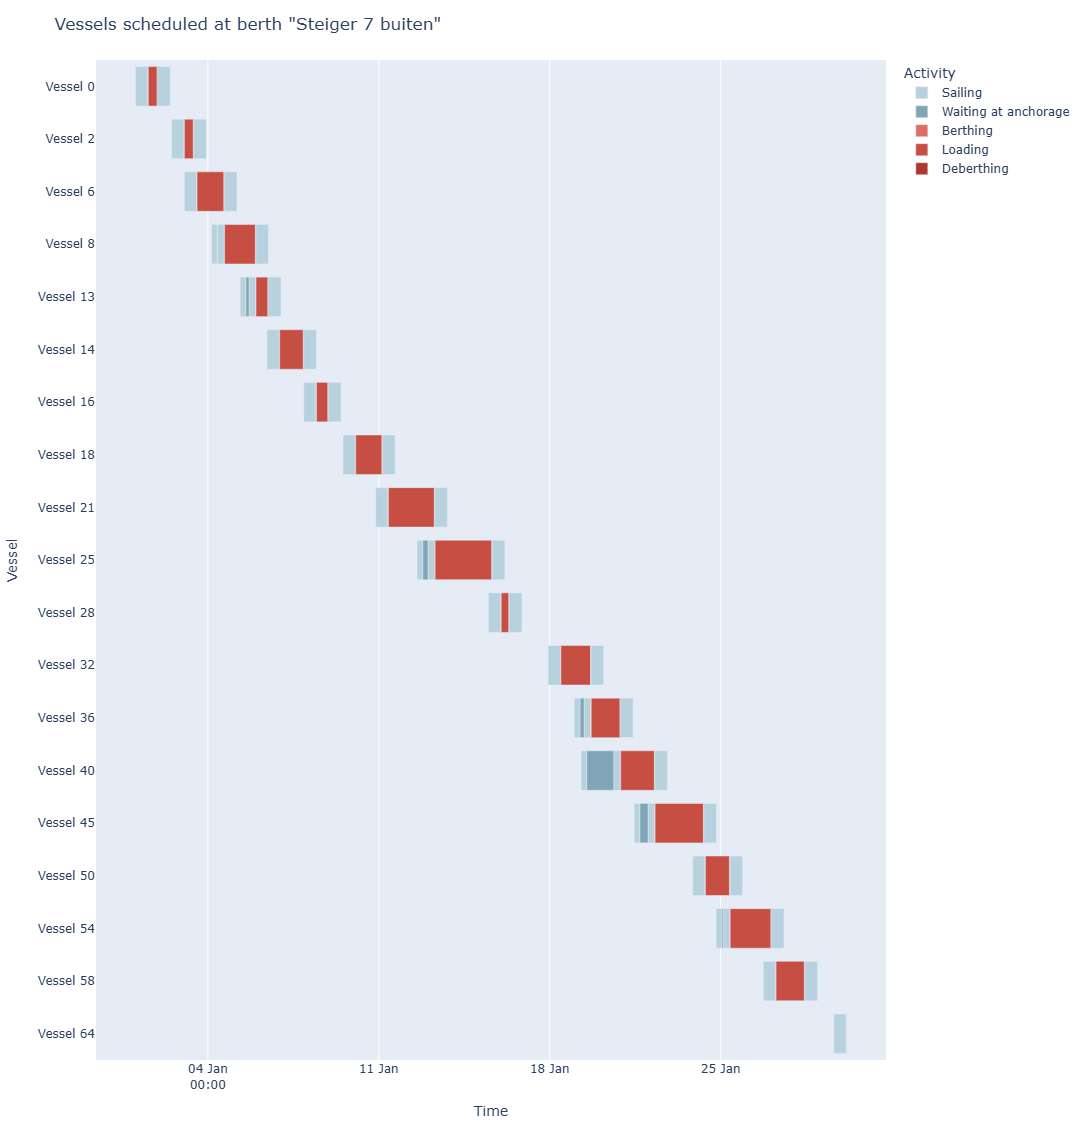

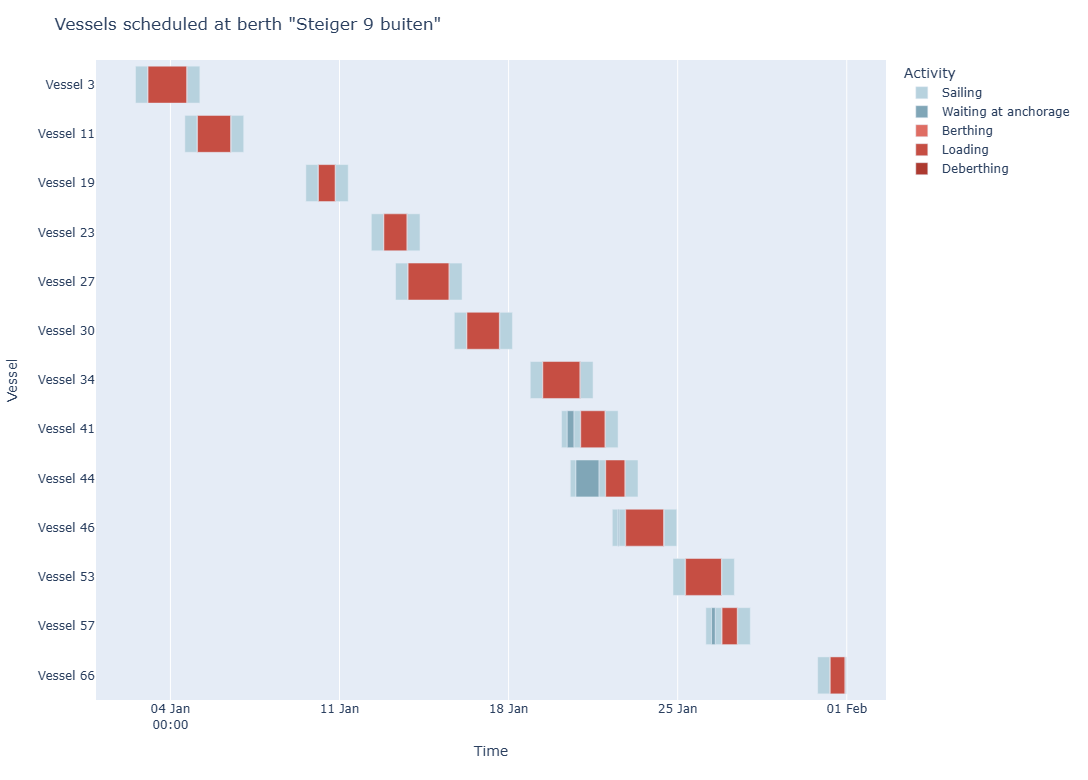

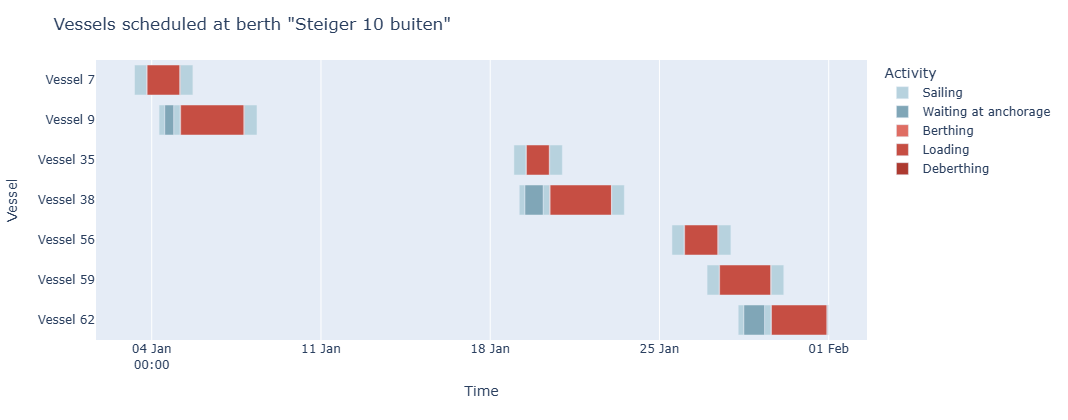

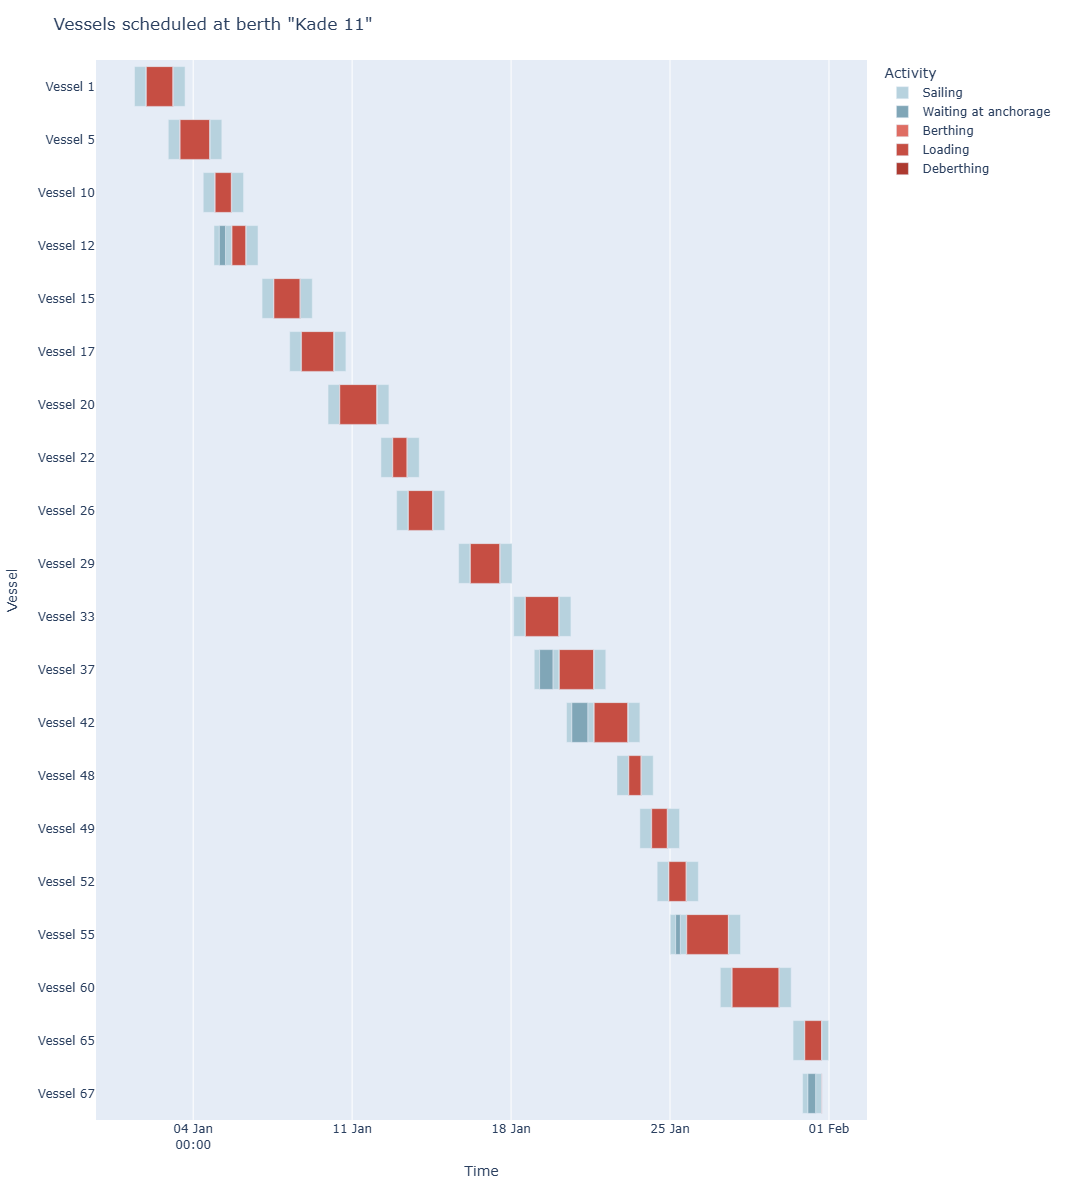

In [25]:
for berth in berths:
    fig = berth.plot_vessel_arrival_timeline()
    fig.show()

In [53]:
waiting_time_causes_terminal = {
    'Terminal congestion': pd.Timedelta(seconds = 0),
    'Tidal windows': pd.Timedelta(seconds = 0),
}
berth_occupancies = []  

cargo_lost = 0.
cargo_operated = 0.
for index, vessel in enumerate(env.vessels['obj']):
    if vessel.arrival_time < env.simulation_stop and len(vessel.trips) == 0:
        cargo_lost += vessels_df.loc[index].cargo_tonnes
    elif len(vessel.trips):
        cargo_operated += vessels_df.loc[index].cargo_tonnes
        
for berth in berths:
    df = berth.get_berth_performance()
    if df.empty:
        continue
    berth_occupancies.append(df['Berth occupancy (%)'])
    waiting_time_causes_berth = df['Causes waiting time']   
    waiting_time_berth_congestion = sum(value for key, value in waiting_time_causes_berth.items() if 'Terminal' in key)
    waiting_time_berth_tidal_windows = sum(value for key, value in waiting_time_causes_berth.items() if 'Tide' in key)
    waiting_time_causes_terminal['Terminal congestion'] += df['Total waiting time']*waiting_time_berth_congestion/100
    waiting_time_causes_terminal['Tidal windows'] += df['Total waiting time']*waiting_time_berth_tidal_windows/100

edge_route = opentnsim.graph.utils.node_path_to_edge_path(env.graph, nodes_shallow_waterway)
channel_distance, _ = opentnsim.graph.utils.get_sailing_distance(env.graph,edge_route)
channel_width = 250.
capital_dredging = deepening*channel_width*channel_distance

performance = {'Total ' + key: value for key, value in waiting_time_causes_terminal.items()}
performance['terminal_occupancy'] = np.mean(berth_occupancies)
performance['cargo_lost'] = cargo_lost
performance['cargo_operated'] = cargo_operated
performance['capital_dredging'] = capital_dredging

In [54]:
performance

{'Total Terminal congestion': Timedelta('2 days 17:47:50.910025'),
 'Total Tidal windows': Timedelta('0 days 00:00:00'),
 'terminal_occupancy': np.float64(57.435394265210576),
 'cargo_lost': 0.0,
 'cargo_operated': np.float64(1554937.0),
 'capital_dredging': np.float64(16593001.552134348)}

In [28]:
vessels_df[vessels_df.draught > 14]

,class,length,beam,draught,cargo_tonnes,transfer_rate_tph,operation_time_hours,mooring_time_hours,demooring_time_hours,interarrival_time_hours,arrival_time_hours,arrival_time
9,Aframax,245.80,42.89,14.38,91868.0,1462.10,62.83,0.47,0.35,3.58,79.30,2026-01-04 07:17:54.704577
61,Panamax,232.94,35.63,14.55,73370.0,865.45,84.78,0.37,0.30,11.00,640.14,2026-01-27 16:08:32.667667


In [144]:
results = pd.DataFrame(columns = [
    'Total Terminal congestion',
    'Total Tidal windows',
    'terminal_occupancy',
    'cargo_lost',
    'cargo_operated',
    'capital_dredging',
])

results.loc[-6.0] = {
    'Total Terminal congestion': pd.Timedelta('1 days 06:09:23.012341'),
    'Total Tidal windows': pd.Timedelta('1 days 08:50:28.444678'),
    'terminal_occupancy': np.float64(33.12083102304361),
    'cargo_lost': np.float64(777646.0),
    'cargo_operated': np.float64(777291.0),
    'capital_dredging': 0,
}

results.loc[-5.0] = {
    'Total Terminal congestion': pd.Timedelta('3 days 11:52:27.647570'),
    'Total Tidal windows': pd.Timedelta('2 days 11:20:03.568753'),
    'terminal_occupancy': np.float64(45.6688875940935),
    'cargo_lost': np.float64(485129.0),
    'cargo_operated': np.float64(1069808.0),
    'capital_dredging': -41482503.88033587,
}

results.loc[-4.0] = {
    'Total Terminal congestion': pd.Timedelta('2 days 15:04:30.719339'),
    'Total Tidal windows': pd.Timedelta('0 days 15:56:11.937919'),
    'terminal_occupancy': np.float64(42.78398956806303),
    'cargo_lost': np.float64(485129.0),
    'cargo_operated': np.float64(1069808.0),
    'capital_dredging': -33186003.104268696,
}

results.loc[-3.0] = {
    'Total Terminal congestion': pd.Timedelta('1 days 07:39:56.498306'),
    'Total Tidal windows': pd.Timedelta('0 days 02:16:57.737784'),
    'terminal_occupancy': np.float64(49.719062304652034),
    'cargo_lost': np.float64(331416.0),
    'cargo_operated': np.float64(1223521.0),
    'capital_dredging': -24889502.32820152,
}

results.loc[-2.0] = {
    'Total Terminal congestion': pd.Timedelta('2 days 05:49:07.385769'),
    'Total Tidal windows': pd.Timedelta('0 days 11:31:00.900821'),
    'terminal_occupancy': np.float64(54.01264993899342),
    'cargo_lost': np.float64(91868.0),
    'cargo_operated': np.float64(1463069.0),
    'capital_dredging': -16593001.552134348,
}

results.loc[-1.0] = {
    'Total Terminal congestion': pd.Timedelta('2 days 09:07:14.053808'),
    'Total Tidal windows': pd.Timedelta('0 days 02:56:20.551335'),
    'terminal_occupancy': np.float64(53.747019335483856),
    'cargo_lost': 0.0,
    'cargo_operated': np.float64(1554937.0),
    'capital_dredging': -8296500.776067174,
}

results.loc[0.0] = {
    'Total Terminal congestion': pd.Timedelta('2 days 21:55:51.627597'),
    'Total Tidal windows': pd.Timedelta('0 days 06:29:24.148359'),
    'terminal_occupancy': np.float64(57.43556003581989),
    'cargo_lost': 0.0,
    'cargo_operated': np.float64(1554937.0),
    'capital_dredging': 0,
}

results.loc[1.0] = {
    'Total Terminal congestion': pd.Timedelta('2 days 17:47:50.910025'),
    'Total Tidal windows': pd.Timedelta('0 days 00:00:00'),
    'terminal_occupancy': np.float64(57.435394265210576),
    'cargo_lost': 0.0,
    'cargo_operated': np.float64(1554937.0),
    'capital_dredging': 8296500.776067174,
}

results.loc[2.0] = {
    'Total Terminal congestion': pd.Timedelta('2 days 17:47:50.910025'),
    'Total Tidal windows': pd.Timedelta('0 days 00:00:00'),
    'terminal_occupancy': np.float64(57.435394265210576),
    'cargo_lost': 0.0,
    'cargo_operated': np.float64(1554937.0),
    'capital_dredging': 16593001.552134348,
}

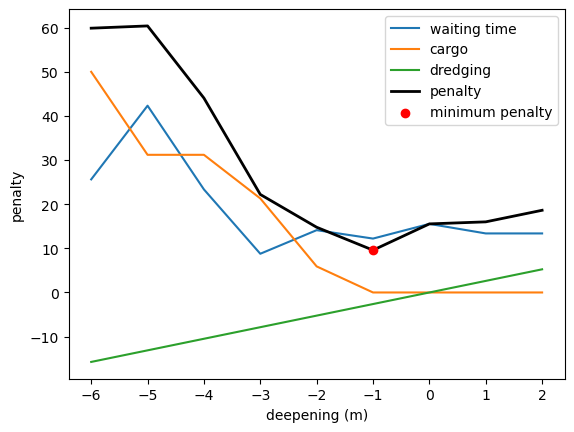

In [213]:
factor_dredging = -6.5
factor_waiting_time = 5.5
factor_cargo = 0

results['cargo_lost %'] = results['cargo_lost'] / (results['cargo_lost'] + results['cargo_operated']) * 100
results['total waiting time'] = (results['Total Terminal congestion'] + results['Total Tidal windows']).apply(lambda x: x.total_seconds()/3600)
results['total waiting time per cargo'] = results['total waiting time'] / results['cargo_operated']
results['waiting time penalty'] = results['total waiting time per cargo']*10**factor_waiting_time
results['dredging penalty'] = results['capital_dredging']*10**factor_dredging
results['cargo penalty'] = results['cargo_lost %']*10**factor_cargo
results['penalty'] = results['cargo penalty'] + results['dredging penalty'] + results['waiting time penalty']

plt.plot(results['waiting time penalty'], label = 'waiting time')
plt.plot(results['cargo penalty'], label = 'cargo')
plt.plot(results['dredging penalty'], label = 'dredging')
plt.plot(results['penalty'], color = 'k', label = 'penalty', linewidth=2)
plt.scatter(results['penalty'].idxmin(), results['penalty'].min(), zorder=100, color = 'red', label = 'minimum penalty')
plt.xlabel('deepening (m)')
plt.ylabel('penalty')
plt.legend();

In [ ]:
#investigate -1 and 0 m